# Where does this neuron fire after accounting for occupancy?

**Question:** Where is firing elevated after accounting for the time the
animal spent at each location, and how does smoothing change the field?

**You will need:** Spike times for one neuron, tracking positions and
timestamps, and an arena boundary. We provide a simulated open-field recording
with a known firing field so that the estimated map has a reference.

**Estimated time**: 20-25 minutes

**Prerequisites**: [01: occupancy](01_getting_started.ipynb).

A cluster of spikes can reflect a firing field, longer dwell time, or both.
We will compare spike locations with occupancy, calculate firing rates, and
outline the field using an explicit rate threshold. This notebook runs
independently and needs no data download.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from neurospatial import Environment
from neurospatial.encoding import compute_spatial_rate, detect_place_fields
from neurospatial.simulation import (
    PlaceCellModel,
    generate_poisson_spikes,
    simulate_trajectory_ou,
)

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (_here / "_style.py").exists() and (_here / "examples" / "_style.py").exists():
    _here = _here / "examples"
if str(_here) not in sys.path:
    sys.path.insert(0, str(_here))
from _style import apply_style

apply_style(figsize=(11, 5))

## 1. A simulated neuron in an open field

The animal moves through an 80 × 80 cm arena for five minutes. We define
5 × 5 cm spatial bins across the whole floor. The neuron's generating rate
profile is Gaussian, centered at `(55, 25)` cm with a width of 10 cm.
Movement and spike generation use different fixed random seeds.

Tracking positions are in centimeters, timestamps are in seconds, and firing
rates are in spikes per second (Hz).

In [2]:
edges = np.arange(0.0, 80.0 + 5.0, 5.0)
env = Environment.from_grid_mask(
    active_mask=np.ones((16, 16), dtype=bool),
    grid_edges=(edges, edges),
    name="Rate-map arena",
)
env.units, env.frame = "cm", "arena"

In [3]:
positions, times = simulate_trajectory_ou(
    env,
    duration=300.0,
    dt=0.01,
    speed_mean=10.0,
    speed_std=2.0,
    coherence_time=0.7,
    boundary_mode="reflect",
    speed_units="cm",
    seed=202,
)
center = np.array([55.0, 25.0])
model = PlaceCellModel(
    env,
    center=center,
    width=10.0,
    max_rate=18.0,
    baseline_rate=0.2,
    metric="euclidean",
)
spike_times = generate_poisson_spikes(
    model.firing_rate(positions, times), times, refractory_period=0.002, seed=203
)

In [4]:
assert np.all(np.diff(times) > 0) and np.all(np.diff(spike_times) >= 0)
assert positions.shape == (len(times), 2)
assert spike_times.min() >= times[0] and spike_times.max() <= times[-1]
print(f"Duration: {times[-1] - times[0]:.2f} s; spikes: {len(spike_times):,}")

Duration: 299.99 s; spikes: 578


## 2. Compare spike locations with occupancy

Plot where each spike occurred beside the occupancy map. We interpolate
tracking onto spike times for this display. The recording has no tracking
gaps; for real data, avoid interpolating through missing tracking periods.

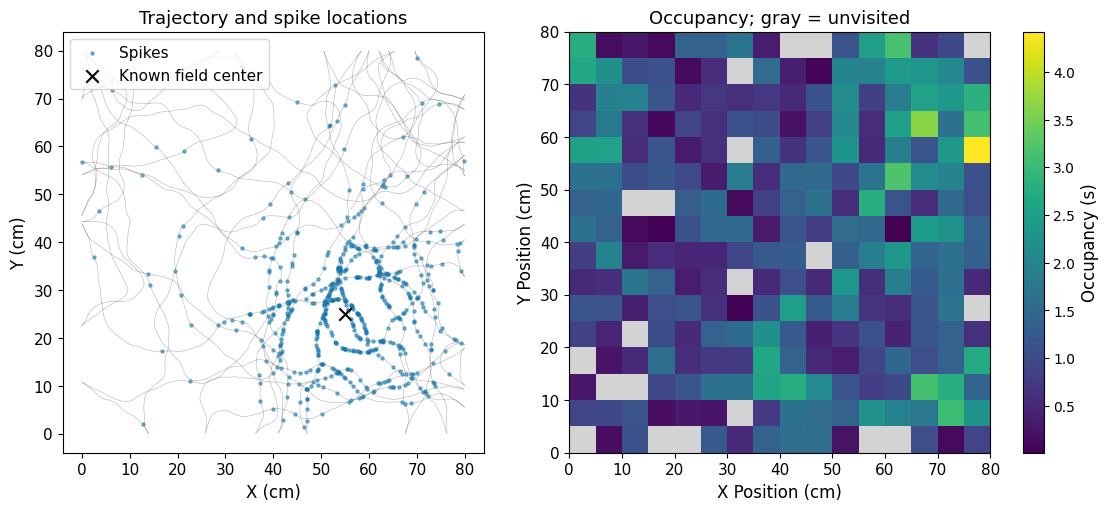

Visited bins: 236 / 256


In [5]:
spike_positions = np.column_stack(
    [np.interp(spike_times, times, positions[:, axis]) for axis in range(2)]
)
occupancy = env.occupancy(times, positions, max_gap=0.05)
fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
axes[0].plot(positions[:, 0], positions[:, 1], color="gray", lw=0.4, alpha=0.6)
axes[0].scatter(*spike_positions.T, s=5, alpha=0.5, label="Spikes")
axes[0].scatter(*center, marker="x", color="black", s=80, label="Known field center")
axes[0].set(xlabel="X (cm)", ylabel="Y (cm)", title="Trajectory and spike locations")
axes[0].set_aspect("equal")
axes[0].legend(loc="upper left")
env.plot_field(
    np.where(occupancy > 0, occupancy, np.nan),
    ax=axes[1],
    cmap="viridis",
    nan_color="lightgray",
    colorbar_label="Occupancy (s)",
)
axes[1].set_title("Occupancy; gray = unvisited")
plt.show()
print(f"Visited bins: {(occupancy > 0).sum()} / {env.n_bins}")
assert np.isclose(occupancy.sum(), times[-1] - times[0])

Spikes cluster around the known field center, while the animal visits much
of the arena. Occupancy varies between locations, and gray bins were never
visited. Firing-rate estimation will account for those differences in dwell
time rather than comparing spike counts alone.

## 3. Calculate an occupancy-normalized firing-rate map

The basic calculation is spike count divided by time spent at each location.
We smooth spike counts and occupancy separately before taking their ratio,
using the same 5 cm smoothing width for both. `method="diffusion_kde"` spreads
information between neighboring bins within the defined arena.

We require at least 0.25 s of raw occupancy per bin. `min_occupancy` sets this
criterion, and `result.spatial_support` records which bins meet it and have a
rate estimate. Rates outside that selection remain missing (`NaN`). For the
unsmoothed map, zero Hz means observed time with no spikes; it is different
from a missing estimate. `max_gap` applies the same tracking-gap rule to
spike counts and occupancy.

In [6]:
settings = {"min_occupancy": 0.25, "max_gap": 0.05}
result = compute_spatial_rate(
    env,
    spike_times,
    times,
    positions,
    method="diffusion_kde",
    bandwidth=5.0,
    **settings,
)
supported_rate = np.where(result.spatial_support, result.firing_rate, np.nan)
raw = compute_spatial_rate(
    env, spike_times, times, positions, method="binned", bandwidth=0.0, **settings
)
print(
    f"Bins meeting the occupancy criterion: {result.spatial_support.sum()} / {env.n_bins}"
)
print(f"Unsmoothed peak: {np.nanmax(raw.firing_rate):.2f} Hz")
print(f"Peak with 5 cm smoothing: {np.nanmax(supported_rate):.2f} Hz")
assert np.allclose(result.occupancy, occupancy)

Bins meeting the occupancy criterion: 219 / 256
Unsmoothed peak: 20.00 Hz
Peak with 5 cm smoothing: 13.92 Hz


## 4. How does smoothing change field width and peak rate?

Keep spatial bins at 5 cm and compare smoothing widths of 2.5, 5, and 10 cm.
The package calls this width `bandwidth`, in the same units as position.
All three panels use the same recording, occupancy criterion, and color scale.

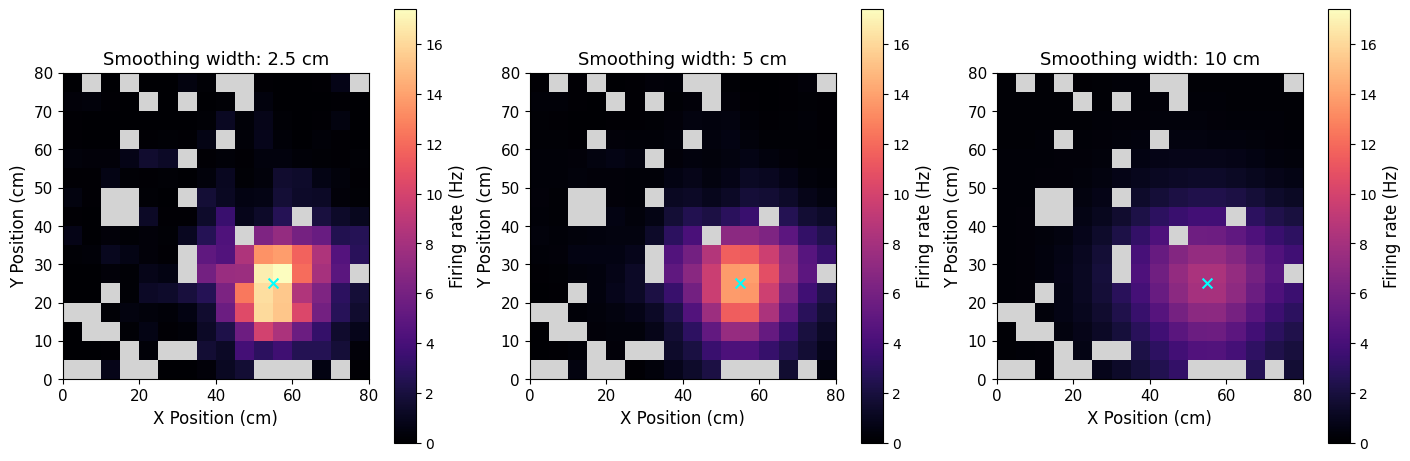

In [7]:
bandwidths = [2.5, 5.0, 10.0]
maps = []
for bandwidth in bandwidths:
    estimate = compute_spatial_rate(
        env,
        spike_times,
        times,
        positions,
        method="diffusion_kde",
        bandwidth=bandwidth,
        **settings,
    )
    maps.append(np.where(estimate.spatial_support, estimate.firing_rate, np.nan))

vmax = max(np.nanmax(rate) for rate in maps)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), layout="constrained")
for ax, bandwidth, rate in zip(axes, bandwidths, maps):
    env.plot_field(
        rate,
        ax=ax,
        cmap="magma",
        vmin=0,
        vmax=vmax,
        nan_color="lightgray",
        colorbar_label="Firing rate (Hz)",
    )
    ax.scatter(*center, marker="x", color="cyan", s=50)
    ax.set_title(f"Smoothing width: {bandwidth:g} cm")
plt.show()

Wider smoothing lowers the estimated peak and broadens the firing profile in
this example. The high-rate area remains near the cyan cross marking the
generating field center. The same gray bins are excluded in every panel, so
the displayed differences come from smoothing rather than a change in visits.

For real recordings, compare smoothing choices using held-out time or repeated
traversals. The [simulation notebook](05_simulation_and_validation.ipynb)
shows how to quantify agreement with a known firing profile.

## 5. Outline the firing field using a stated threshold

Use the 5 cm smoothed map and group neighboring bins above 30% of its peak.
`detect_place_fields()` returns the bin indices for each field. We require
at least four 5 × 5 cm bins, giving a minimum area of 100 cm².

Fields meeting the rate and area criteria: 1
  Field 1: area 950 cm², peak rate 13.92 Hz


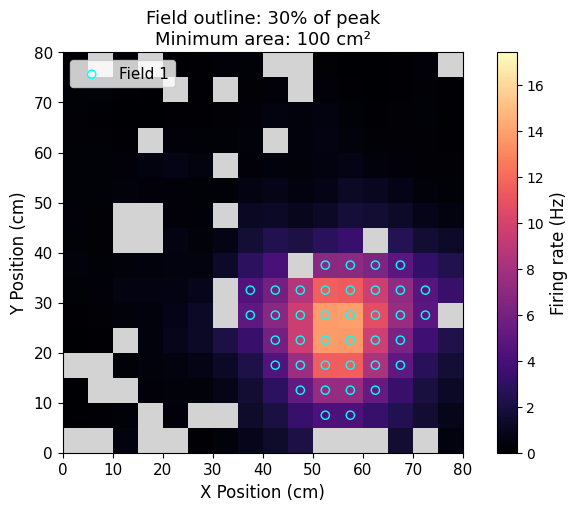

In [8]:
fields = detect_place_fields(env, supported_rate, threshold=0.3, min_size=4)
print(f"Fields meeting the rate and area criteria: {len(fields)}")
for number, bins in enumerate(fields, start=1):
    area = env.bin_sizes[bins].sum()
    peak = np.nanmax(supported_rate[bins])
    print(f"  Field {number}: area {area:.0f} cm², peak rate {peak:.2f} Hz")

fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
env.plot_field(
    supported_rate,
    ax=ax,
    cmap="magma",
    vmin=0,
    vmax=vmax,
    nan_color="lightgray",
    colorbar_label="Firing rate (Hz)",
)
for number, bins in enumerate(fields, start=1):
    ax.scatter(
        *env.bin_centers[bins].T,
        facecolors="none",
        edgecolors="cyan",
        s=35,
        label=f"Field {number}",
    )
if fields:
    ax.legend(loc="upper left")
ax.set_title("Field outline: 30% of peak\nMinimum area: 100 cm²")
plt.show()

The cyan circles outline one high-rate area around the known center. Its
boundary depends on the chosen smoothing width, rate threshold, and minimum
area. This defines a field on the estimated map. Claims about place-cell
identity require additional evidence, such as repeatability and a statistical
comparison appropriate to the experiment.

## Use your own recording

Replace `spike_times` with a sorted spike-time array in seconds. Replace
`times` and `positions` with aligned tracking timestamps and `(x, y)` positions.
Spikes and tracking must share a clock. Define the arena in the same calibrated
coordinates and choose bin width for the spatial features you want to resolve.

Report the smoothing width, minimum occupancy, and gap threshold with the map.
Inspect which locations meet the occupancy criterion. If analysis is restricted
to running or selected trials, pass the same `epochs=` windows for spikes and
occupancy. Supply `spike_window=` when acquisition intervals are known,
especially if spike recording and tracking cover different periods.

[03: running bouts and traversals](03_trajectories_and_behavior.ipynb) defines
behavioral windows. Use `compute_spatial_rates()` for several neurons, as in
[04: a hippocampal recording](04_real_data_analysis.ipynb), or continue to
[06: position decoding](06_position_decoding.ipynb). The
[rate-estimation guide](https://edeno.github.io/neurospatial/user-guide/spike-field-primitives/)
explains other estimators and analysis choices.